# Bidirectional wavefront alignment

Run BiWFA from WFA2-lib on sequence pairs with known edits and verify its cost with an independent dynamic programme.

BiWFA advances wavefronts from both ends, locates an optimal overlap and reconstructs the alignment by recursion. The ultralow mode implements this strategy. The test disables heuristic pruning and charges 2 for a substitution and 3 plus the gap length for a gap.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from tempfile import TemporaryDirectory
import shutil, subprocess, re
from genome_methods import gotoh, rng_dna

## Compare native and reference costs

Build WFA2-lib v2.3.6 and place its align_benchmark executable on PATH. The input file uses one sequence pair per two lines.

pair 1: cost 0, CIGAR 90M
pair 2: cost 6, CIGAR 32M3I58M
pair 3: cost 8, CIGAR 45M5D40M
pair 4: cost 4, CIGAR 14M2X74M
pair 5: cost 13, CIGAR 20M3D28M4I39M


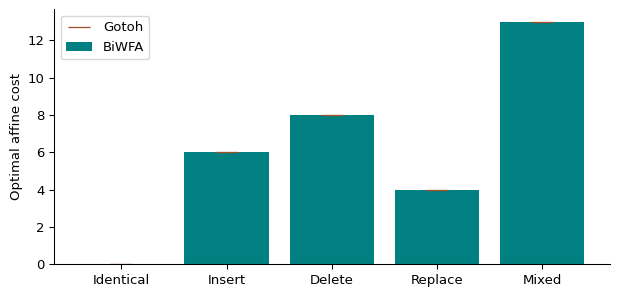

In [2]:
rng = np.random.default_rng(19)
base = rng_dna(rng, 90)
pairs = [
    (base, base),
    (base, base[:30] + "GGG" + base[30:]),
    (base, base[:45] + base[50:]),
    (base, base[:12] + "TTAC" + base[16:]),
    (base, base[:20] + base[23:51] + "ATTT" + base[51:]),
]
binary = shutil.which("align_benchmark")
if not binary:
    raise FileNotFoundError("Build WFA2-lib and add its bin directory to PATH")
with TemporaryDirectory() as temp:
    work = Path(temp)
    inp = work / "pairs.seq"
    out = work / "scores.tsv"
    inp.write_text("".join(f">{a}\n<{b}\n" for a, b in pairs))
    subprocess.run(
        [
            binary,
            "-a",
            "gap-affine-wfa",
            "--wfa-memory",
            "ultralow",
            "--wfa-heuristic",
            "none",
            "-g",
            "0,2,3,1",
            "-i",
            str(inp),
            "-o",
            str(out),
            "-q",
        ],
        check=True,
        capture_output=True,
        text=True,
    )
    records = [line.split() for line in out.read_text().splitlines()]
native = [-int(row[0]) for row in records]
exact = [gotoh(a, b)[0] for a, b in pairs]
assert native == exact
for i, (score, cigar) in enumerate(records):
    print(f"pair {i+1}: cost {-int(score)}, CIGAR {cigar}")
fig, ax = plt.subplots(figsize=(6.4, 3), constrained_layout=True)
ix = np.arange(len(pairs))
ax.bar(ix, native, color="teal", label="BiWFA")
ax.plot(ix, exact, "_", ms=16, color="sienna", label="Gotoh")
ax.set(
    xticks=ix,
    xticklabels=["Identical", "Insert", "Delete", "Replace", "Mixed"],
    ylabel="Optimal affine cost",
)
ax.legend()
plt.show()

## Interpreting the result

The cost agrees even when multiple traceback paths are optimal. The short fixture verifies scoring and command configuration. It does not measure a performance crossover.

## Exercise

Repeat with a longer gap and predict the marginal cost of each additional base.

## References

[Marco-Sola et al., optimal gap-affine alignment in O(s) space](https://doi.org/10.1093/bioinformatics/btad074)

[WFA2-lib, installation and memory modes](https://github.com/smarco/WFA2-lib)